In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv(r"C:\Users\Admin\OneDrive\Desktop\mathametics exam 1\loan_applications_5000_records.csv")

print(df.head())

print("Dataset Shape:", df.shape)

print(df.columns.tolist())

  Customer_ID  Age  Income  Loan_Amount  Credit_Score  Loan_Term_months  \
0   CUST00001   42  574000       975000           650                24   
1   CUST00002   28  563000       475000           810                60   
2   CUST00003   47  465000       925000           810                12   
3   CUST00004   49  798000       620000           566                36   
4   CUST00005   21  727000       645000           775                60   

  Default_Status  
0             No  
1             No  
2             No  
3             No  
4             No  
Dataset Shape: (5000, 7)
['Customer_ID', 'Age', 'Income', 'Loan_Amount', 'Credit_Score', 'Loan_Term_months', 'Default_Status']


In [3]:
mean_income = df["Income"].mean()
median_income = df["Income"].median()
mode_income = df["Income"].mode()

print("Mean Income:", mean_income)
print("Median Income:", median_income)
print("Mode Income:", mode_income.tolist())

Mean Income: 730896.0
Median Income: 644000.0
Mode Income: [594000]


In [4]:
loan_range = df["Loan_Amount"].max() - df["Loan_Amount"].min()
loan_variance = df["Loan_Amount"].var()
loan_std = df["Loan_Amount"].std()

print("Loan Amount Range:", loan_range)
print("Loan Amount Variance:", loan_variance)
print("Loan Amount Standard Deviation:", loan_std)

Loan Amount Range: 2475000
Loan Amount Variance: 332041334490.8982
Loan Amount Standard Deviation: 576230.2790472731


In [5]:
total_customers = len(df)

default_customers = (df["Default_Status"] == "Yes").sum()

default_probability = default_customers / total_customers

print("Total Customers:", total_customers)
print("Default Customers:", default_customers)
print("Probability of Loan Default:", default_probability)
print("Default Probability (%):", default_probability * 100)

Total Customers: 5000
Default Customers: 515
Probability of Loan Default: 0.103
Default Probability (%): 10.299999999999999


In [6]:
credit_bins = [0, 599, 699, 799, 850]
credit_labels = [
    "Below 600",
    "600-699",
    "700-799",
    "800-850"
]

df["Credit_Range"] = pd.cut(
    df["Credit_Score"],
    bins=credit_bins,
    labels=credit_labels,
    include_lowest=True
)

contingency_table = pd.crosstab(
    df["Credit_Range"],
    df["Default_Status"]
)

print("Contingency Table:")
print(contingency_table)

Contingency Table:
Default_Status    No  Yes
Credit_Range             
Below 600        376  127
600-699         2244  299
700-799         1684   87
800-850          181    2


In [7]:
low_credit_customers = df[df["Credit_Score"] < 600]

if len(low_credit_customers) > 0:
    low_credit_defaults = (
        low_credit_customers["Default_Status"] == "Yes"
    ).sum()

    conditional_probability = (
        low_credit_defaults / len(low_credit_customers)
    )

    print("Customers with Credit Score < 600:",
          len(low_credit_customers))

    print("Defaults among them:", low_credit_defaults)

    print("P(Default | Credit Score < 600):",
          conditional_probability)

    print("Conditional Probability (%):",
          conditional_probability * 100)
else:
    print("No customers found with Credit Score below 600.")

Customers with Credit Score < 600: 503
Defaults among them: 127
P(Default | Credit Score < 600): 0.2524850894632207
Conditional Probability (%): 25.24850894632207


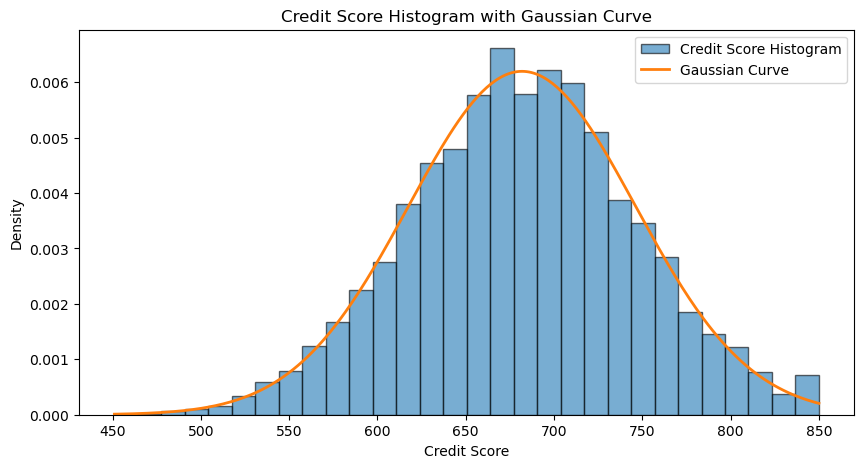

In [8]:
credit_scores = df["Credit_Score"].dropna()

mean_score = credit_scores.mean()
std_score = credit_scores.std()

plt.figure(figsize=(10, 5))

plt.hist(
    credit_scores,
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Credit Score Histogram"
)

x = np.linspace(
    credit_scores.min(),
    credit_scores.max(),
    300
)

y = stats.norm.pdf(x, mean_score, std_score)

plt.plot(x, y, linewidth=2, label="Gaussian Curve")

plt.title("Credit Score Histogram with Gaussian Curve")
plt.xlabel("Credit Score")
plt.ylabel("Density")
plt.legend()
plt.show()

In [9]:
loan_amounts = df["Loan_Amount"].dropna()

skewness = loan_amounts.skew()
kurtosis = loan_amounts.kurt()

print("Loan Amount Skewness:", skewness)
print("Loan Amount Kurtosis:", kurtosis)

Loan Amount Skewness: 0.9749345371687934
Loan Amount Kurtosis: 0.48243789267781745


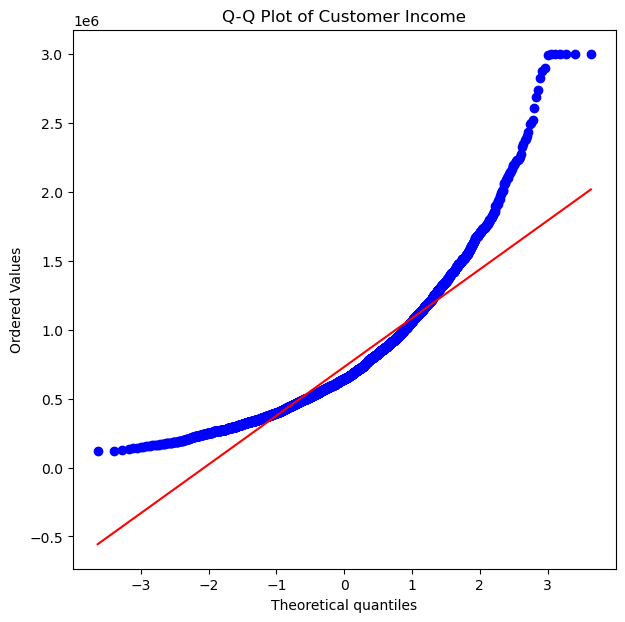

In [10]:
income_values = df["Income"].dropna()

plt.figure(figsize=(7, 7))

stats.probplot(
    income_values,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Customer Income")
plt.show()

In [11]:
first_five = df[["Income", "Loan_Amount"]].head(5)

vectors = first_five.to_numpy(dtype=float)

print("First 5 Customers:")
print(first_five)

print("\nFinancial Vectors:")
print(vectors)

First 5 Customers:
   Income  Loan_Amount
0  574000       975000
1  563000       475000
2  465000       925000
3  798000       620000
4  727000       645000

Financial Vectors:
[[574000. 975000.]
 [563000. 475000.]
 [465000. 925000.]
 [798000. 620000.]
 [727000. 645000.]]


In [12]:
vector_1 = vectors[0]
vector_2 = vectors[1]

dot_product = np.dot(vector_1, vector_2)

print("Customer 1 Vector:", vector_1)
print("Customer 2 Vector:", vector_2)
print("Dot Product:", dot_product)

Customer 1 Vector: [574000. 975000.]
Customer 2 Vector: [563000. 475000.]
Dot Product: 786287000000.0


In [13]:
customer_vector = vectors[0]

norm_2 = np.linalg.norm(customer_vector, ord=2)

print("Customer 1 Vector:", customer_vector)
print("Norm 2:", norm_2)

Customer 1 Vector: [574000. 975000.]
Norm 2: 1131415.485133556


In [14]:
vector_1 = vectors[0]
vector_2 = vectors[1]

dot_product = np.dot(vector_1, vector_2)

norm_1 = np.linalg.norm(vector_1)
norm_2 = np.linalg.norm(vector_2)

if norm_1 > 0 and norm_2 > 0:
    cosine_angle = dot_product / (norm_1 * norm_2)

    # Floating-point errors ટાળવા માટે
    cosine_angle = np.clip(cosine_angle, -1, 1)

    angle_radians = np.arccos(cosine_angle)
    angle_degrees = np.degrees(angle_radians)

    print("Angle in Radians:", angle_radians)
    print("Angle in Degrees:", angle_degrees)
else:
    print("Angle cannot be calculated for a zero vector.")

Angle in Radians: 0.33789177278820925
Angle in Degrees: 19.359772512957747
